<a href="https://colab.research.google.com/github/mukulyadav0118/india-school-education-analytics/blob/main/01_data_inspection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# India School Education Equity & Infrastructure Analytics

## 1. Introduction

Education plays an important role in social and economic development. However, schools may differ in infrastructure, classroom conditions, teacher availability, and student enrolment.

This project uses official UDISE+ (Unified District Information System for Education Plus) school-level data to investigate variations in school education across Indian states and districts.

The analysis will focus on identifying infrastructure gaps, examining teacher and enrolment patterns, and discovering groups of districts with similar education profiles.

The findings will be used to develop evidence-based insights that may support education planning and resource allocation.

## 2. Project Objectives

1. Inspect and validate school-level education datasets.
2. Integrate compatible datasets using verified school identifiers.
3. Analyze school infrastructure, teacher availability, and enrolment.
4. Investigate patterns, outliers, missing values, and regional disparities.
5. Apply appropriate statistical methods and clustering techniques.
6. Develop visualizations and an interactive dashboard.
7. Present actionable recommendations supported by the analysis.

## 3. Research Questions

- How does school infrastructure vary across districts?
- Which districts show potential gaps in teacher availability?
- How do enrolment patterns differ across schools and regions?
- Can districts be grouped by their infrastructure and education indicators?
- What evidence-based priorities can be identified for education planning?

## 4. Expected Outcome

A reproducible data analysis workflow, supported by statistical investigation, explanatory visualizations, clustering, and an interactive dashboard.


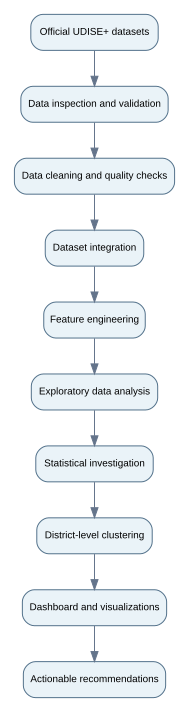

In [1]:

!pip -q install graphviz

from graphviz import Digraph
from IPython.display import display

workflow = Digraph("Project_Workflow", format="png")
workflow.attr(rankdir="TB", bgcolor="white", pad="0.2")
workflow.attr("node", shape="box", style="rounded,filled",
              fontname="Arial", fontsize="10",
              color="#52718A", fillcolor="#EAF3F8")
workflow.attr("edge", color="#64748B")

steps = [
    ("A", "Official UDISE+ datasets"),
    ("B", "Data inspection and validation"),
    ("C", "Data cleaning and quality checks"),
    ("D", "Dataset integration"),
    ("E", "Feature engineering"),
    ("F", "Exploratory data analysis"),
    ("G", "Statistical investigation"),
    ("H", "District-level clustering"),
    ("I", "Dashboard and visualizations"),
    ("J", "Actionable recommendations")
]

for node_id, label in steps:
    workflow.node(node_id, label)

for i in range(len(steps) - 1):
    workflow.edge(steps[i][0], steps[i + 1][0])

display(workflow)


In [2]:

import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
from IPython.display import display

drive.mount("/content/drive")

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Mounted at /content/drive
Libraries imported successfully.
Pandas version: 2.2.3
NumPy version: 2.1.3


In [3]:

data_path = "/content/drive/MyDrive/India_School_Education_Data"

if os.path.isdir(data_path):
    print("Dataset folder found.")
    print("State folders:", sorted(
        name for name in os.listdir(data_path)
        if os.path.isdir(os.path.join(data_path, name))
    ))
else:
    print("Dataset folder not found. Check the Drive path.")


Dataset folder found.
State folders: ['bihar', 'chhattisgarh', 'haryana', 'jharkhand', 'mp', 'rajasthan', 'up']


In [4]:

csv_files = []

for state in os.listdir(data_path):
    extracted_path = os.path.join(data_path, state, "extracted")

    if not os.path.isdir(extracted_path):
        continue

    for root, dirs, files in os.walk(extracted_path):
        for file in files:
            if file.lower().endswith(".csv"):
                csv_files.append({
                    "State": state,
                    "File": file,
                    "Path": os.path.join(root, file)
                })

csv_index = pd.DataFrame(csv_files)

print("Total CSV files found:", len(csv_files))
display(csv_index[["State", "File"]])


Total CSV files found: 28


,State,File
0,up,09_fac.csv
1,up,09_enr2.csv
2,up,09_tch.csv
3,up,09_prof1.csv
4,mp,23_enr2.csv
5,mp,23_prof1.csv
6,mp,23_fac.csv
7,mp,23_tch.csv
8,haryana,06_enr2.csv
9,haryana,06_tch.csv


In [5]:

summary = []

for item in csv_files:
    try:
        df = pd.read_csv(item["Path"], low_memory=False)

        summary.append({
            "State": item["State"],
            "File": item["File"],
            "Rows": len(df),
            "Columns": len(df.columns),
            "Has pseudocode": "pseudocode" in df.columns,
            "Duplicate pseudocodes": (
                int(df["pseudocode"].duplicated().sum())
                if "pseudocode" in df.columns else None
            ),
            "Missing cells": int(df.isna().sum().sum())
        })

        del df

    except Exception as e:
        print(f"Could not read {item['File']}: {e}")

summary_df = pd.DataFrame(summary)
display(summary_df)


,State,File,Rows,Columns,Has pseudocode,Duplicate pseudocodes,Missing cells
0,up,09_fac.csv,265278,82,True,0,119914
1,up,09_enr2.csv,2491171,42,True,2226206,0
2,up,09_tch.csv,265278,38,True,0,0
3,up,09_prof1.csv,265278,49,True,0,591108
4,mp,23_enr2.csv,1078230,42,True,958536,0
5,mp,23_prof1.csv,119694,49,True,0,261455
6,mp,23_fac.csv,119694,82,True,0,28005
7,mp,23_tch.csv,119694,38,True,0,0
8,haryana,06_enr2.csv,240115,42,True,216636,0
9,haryana,06_tch.csv,23479,38,True,0,0
